# Synergy – Modelo predictivo de riesgo de proyectos

**Proyecto de aula · Sección 1830**
Nictor Manuel Cañate Valdés · Margelis Ávila Martínez · Dairys Díaz López · Natalia Castilla Álvarez

**Objetivo:** clasificar si un proyecto ambiental tiene riesgo **Bajo, Medio o Alto** de no cumplir sus objetivos (variable `nivel_riesgo`).

**Flujo de trabajo**
1. Cargar el dataset exportado desde Synergy (panel del administrador → *Modelo predictivo* → *Descargar CSV*).
2. Explorar los datos (pandas + matplotlib).
3. Preparar los datos (numpy).
4. Entrenar y comparar tres modelos de clasificación.
5. Evaluar con exactitud, matriz de confusión, precisión y recall por clase.
6. Exportar el modelo elegido a código Java (`ModeloRiesgo.java`) para usarlo dentro de Synergy.

> **Cómo se construyó el dataset:** cada fila es un proyecto **ya terminado**. Las variables se miden **a la mitad del proyecto** y `nivel_riesgo` se calcula con **cómo terminó** (reglas de la propuesta). Así el modelo aprende a *anticipar* el riesgo y no solo a copiar la regla.

In [1]:
# En Google Colab m2cgen no viene instalado
%pip install -q m2cgen

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True
SEMILLA = 42
np.random.seed(SEMILLA)

## 1. Cargar los datos

In [3]:
ARCHIVO = 'dataset_riesgo_synergy.csv'

# En Colab: si el archivo no está, se pide subirlo
if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files
        subido = files.upload()
        ARCHIVO = next(iter(subido))
    except ImportError:
        raise FileNotFoundError('Descarga el CSV desde Synergy y ponlo junto a este notebook')

df = pd.read_csv(ARCHIVO)
print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (600, 12)


,codigo,categoria,dias_retraso,pct_tareas_pendientes,participantes,tasa_participacion,duracion_dias,avance_real,avance_esperado,brecha_avance,actividades,nivel_riesgo
0,SYN-2025-00001,Espacios verdes,0,0.667,3,0.333,169,0.333,0.497,-0.164,2,Alto
1,SYN-2025-00002,Reforestación,8,0.875,8,0.750,105,0.125,0.495,-0.370,8,Medio
2,SYN-2026-00003,Energía limpia,0,0.500,10,1.000,104,0.500,0.500,0.000,15,Alto
3,SYN-2026-00004,Agua y saneamiento,41,0.857,5,0.400,180,0.143,0.500,-0.357,4,Alto
4,SYN-2024-00005,Calidad del aire,0,0.500,8,0.625,173,0.500,0.497,0.003,9,Bajo


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   codigo                 600 non-null    str    
 1   categoria              600 non-null    str    
 2   dias_retraso           600 non-null    int64  
 3   pct_tareas_pendientes  600 non-null    float64
 4   participantes          600 non-null    int64  
 5   tasa_participacion     600 non-null    float64
 6   duracion_dias          600 non-null    int64  
 7   avance_real            600 non-null    float64
 8   avance_esperado        600 non-null    float64
 9   brecha_avance          600 non-null    float64
 10  actividades            600 non-null    int64  
 11  nivel_riesgo           600 non-null    str    
dtypes: float64(5), int64(4), str(3)
memory usage: 56.4 KB


In [5]:
print('Valores nulos por columna:')
print(df.isna().sum())
print('\nFilas duplicadas:', df.duplicated().sum())

Valores nulos por columna:
codigo                   0
categoria                0
dias_retraso             0
pct_tareas_pendientes    0
participantes            0
tasa_participacion       0
duracion_dias            0
avance_real              0
avance_esperado          0
brecha_avance            0
actividades              0
nivel_riesgo             0
dtype: int64

Filas duplicadas: 0


## 2. Exploración de los datos

In [6]:
df.describe().round(2)

,dias_retraso,pct_tareas_pendientes,participantes,tasa_participacion,duracion_dias,avance_real,avance_esperado,brecha_avance,actividades
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00
mean,6.07,0.64,6.41,0.59,113.02,0.36,0.50,-0.13,6.95
std,11.25,0.26,2.23,0.25,39.21,0.26,0.00,0.26,3.77
min,0.00,0.00,3.00,0.00,45.00,0.00,0.49,-0.50,0.00
25%,0.00,0.46,4.00,0.40,80.75,0.17,0.50,-0.33,4.00
50%,0.00,0.67,6.00,0.61,113.50,0.33,0.50,-0.16,7.00
75%,7.00,0.83,8.00,0.75,146.00,0.55,0.50,0.05,10.00
max,61.00,1.00,10.00,1.00,180.00,1.00,0.50,0.50,19.00


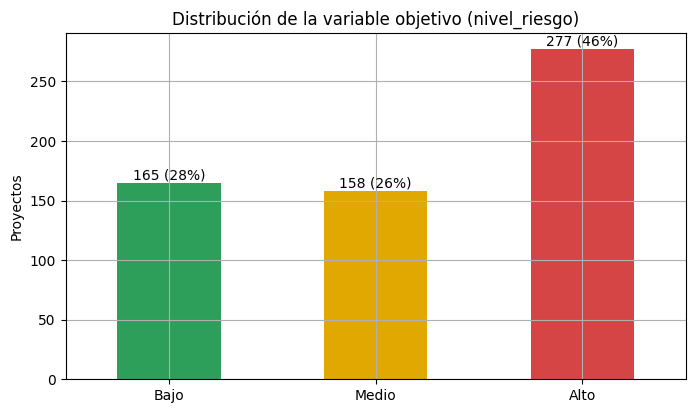

In [7]:
ORDEN = ['Bajo', 'Medio', 'Alto']
COLORES = {'Bajo': '#2e9e5b', 'Medio': '#e0a800', 'Alto': '#d64545'}

conteo = df['nivel_riesgo'].value_counts().reindex(ORDEN)
ax = conteo.plot(kind='bar', color=[COLORES[n] for n in ORDEN], rot=0)
ax.set_title('Distribución de la variable objetivo (nivel_riesgo)')
ax.set_xlabel(''); ax.set_ylabel('Proyectos')
for i, v in enumerate(conteo):
    ax.text(i, v + 3, f'{v} ({v / len(df):.0%})', ha='center')
plt.show()

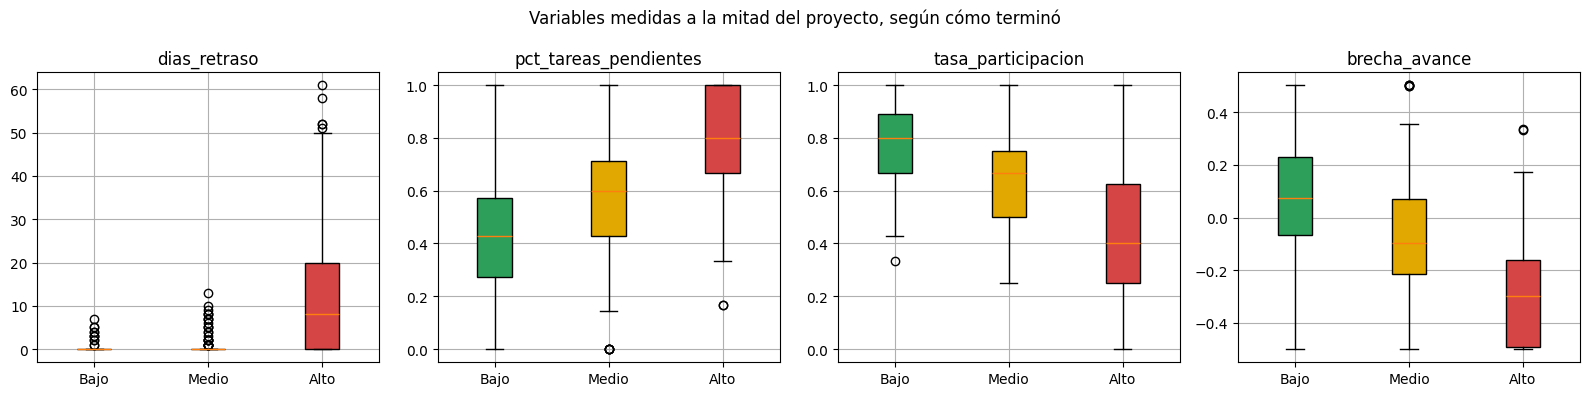

In [8]:
variables = ['dias_retraso', 'pct_tareas_pendientes', 'tasa_participacion', 'brecha_avance']
fig, ejes = plt.subplots(1, 4, figsize=(16, 4))
for ax, var in zip(ejes, variables):
    datos = [df.loc[df['nivel_riesgo'] == n, var] for n in ORDEN]
    caja = ax.boxplot(datos, patch_artist=True)
    ax.set_xticks([1, 2, 3], ORDEN)
    for parche, n in zip(caja['boxes'], ORDEN):
        parche.set_facecolor(COLORES[n])
    ax.set_title(var)
fig.suptitle('Variables medidas a la mitad del proyecto, según cómo terminó')
plt.tight_layout(); plt.show()

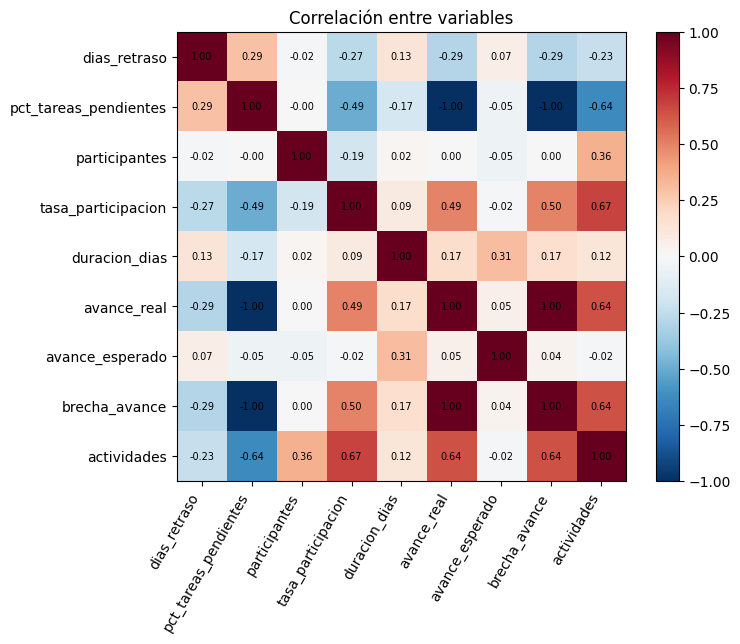

In [9]:
numericas = ['dias_retraso', 'pct_tareas_pendientes', 'participantes', 'tasa_participacion',
             'duracion_dias', 'avance_real', 'avance_esperado', 'brecha_avance', 'actividades']
corr = df[numericas].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas)), numericas, rotation=60, ha='right')
ax.set_yticks(range(len(numericas)), numericas)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
ax.grid(False)
plt.colorbar(im); ax.set_title('Correlación entre variables'); plt.tight_layout(); plt.show()

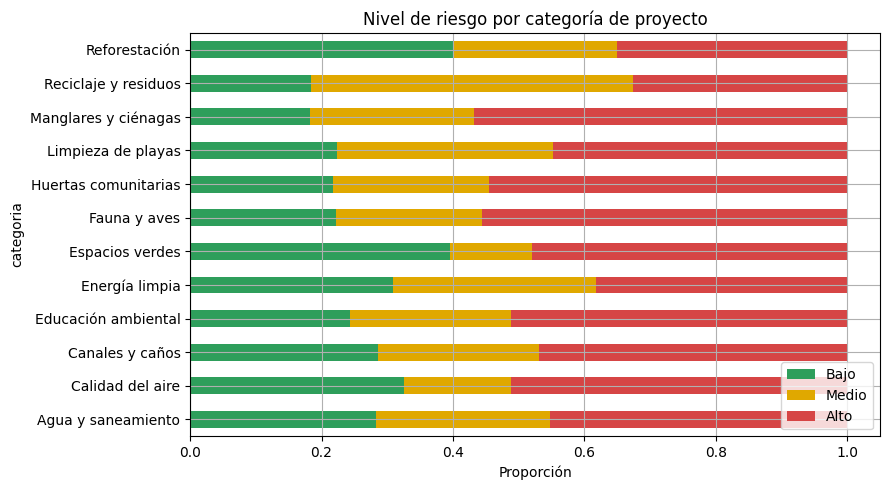

In [10]:
tabla = pd.crosstab(df['categoria'], df['nivel_riesgo'], normalize='index')[ORDEN]
tabla.plot(kind='barh', stacked=True, color=[COLORES[n] for n in ORDEN], figsize=(9, 5))
plt.title('Nivel de riesgo por categoría de proyecto'); plt.xlabel('Proporción'); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

## 3. Preparación de los datos

- `avance_real` es exactamente `1 - pct_tareas_pendientes`, pero se deja porque el modelo en Java recibe las mismas variables.
- La categoría se convierte en columnas 0/1 (**one-hot**) **en el mismo orden** que usa Synergy (`Catalogos.CATEGORIAS`), para que el modelo exportado reciba el vector igual.
- La variable objetivo se codifica así: **0 = Bajo, 1 = Medio, 2 = Alto**.

In [11]:
CATEGORIAS = ['Limpieza de playas', 'Reforestación', 'Manglares y ciénagas', 'Reciclaje y residuos',
              'Huertas comunitarias', 'Educación ambiental', 'Fauna y aves', 'Agua y saneamiento',
              'Energía limpia', 'Espacios verdes', 'Calidad del aire', 'Canales y caños']

def construir_X(datos):
    X_num = datos[numericas].to_numpy(dtype=float)
    X_cat = np.zeros((len(datos), len(CATEGORIAS)))
    for i, c in enumerate(datos['categoria']):
        if c in CATEGORIAS:
            X_cat[i, CATEGORIAS.index(c)] = 1
    return np.hstack([X_num, X_cat])

COLUMNAS = numericas + ['cat_' + c for c in CATEGORIAS]
X = construir_X(df)
y = df['nivel_riesgo'].map({'Bajo': 0, 'Medio': 1, 'Alto': 2}).to_numpy()

X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
print('Entrenamiento:', X_ent.shape, ' Prueba:', X_pru.shape)
print('Clases en entrenamiento:', np.bincount(y_ent), ' en prueba:', np.bincount(y_pru))

Entrenamiento: (450, 21)  Prueba: (150, 21)
Clases en entrenamiento: [124 118 208]  en prueba: [41 40 69]


## 4. Entrenamiento y comparación de modelos

Se comparan tres modelos con validación cruzada de 5 particiones (métrica: **F1 macro**, que da el mismo peso a las tres clases).

In [12]:
modelos = {
    'Árbol de decisión': DecisionTreeClassifier(max_depth=5, min_samples_leaf=8, class_weight='balanced', random_state=SEMILLA),
    'Random forest': RandomForestClassifier(n_estimators=40, max_depth=6, min_samples_leaf=5, class_weight='balanced', random_state=SEMILLA),
    'Regresión logística': LogisticRegression(max_iter=5000, class_weight='balanced'),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
resultados = []
for nombre, modelo in modelos.items():
    f1_cv = cross_val_score(modelo, X_ent, y_ent, cv=cv, scoring='f1_macro')
    modelo.fit(X_ent, y_ent)
    pred = modelo.predict(X_pru)
    resultados.append({'modelo': nombre, 'F1 macro (CV)': f1_cv.mean(), 'desv. CV': f1_cv.std(),
                       'exactitud (prueba)': accuracy_score(y_pru, pred), 'F1 macro (prueba)': f1_score(y_pru, pred, average='macro')})
tabla_res = pd.DataFrame(resultados).set_index('modelo').round(3)
tabla_res

,F1 macro (CV),desv. CV,exactitud (prueba),F1 macro (prueba)
modelo,,,,
Árbol de decisión,0.670,0.016,0.667,0.649
Random forest,0.672,0.034,0.733,0.697
Regresión logística,0.675,0.016,0.700,0.674


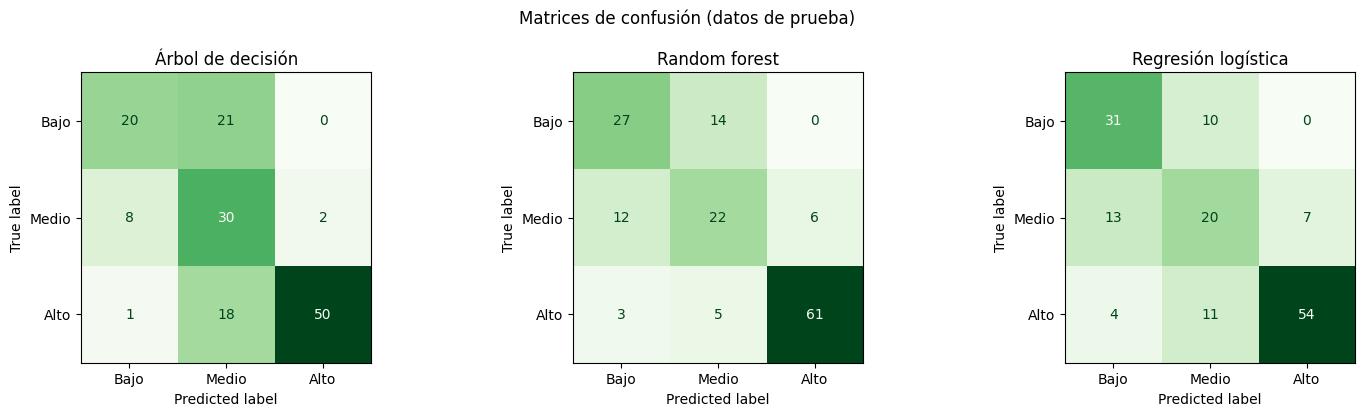

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (nombre, modelo) in zip(ejes, modelos.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_pru, modelo.predict(X_pru)), display_labels=ORDEN).plot(ax=ax, cmap='Greens', colorbar=False)
    ax.set_title(nombre); ax.grid(False)
plt.suptitle('Matrices de confusión (datos de prueba)'); plt.tight_layout(); plt.show()

In [14]:
for nombre, modelo in modelos.items():
    print('=' * 60); print(nombre)
    print(classification_report(y_pru, modelo.predict(X_pru), target_names=ORDEN, digits=3))

Árbol de decisión
              precision    recall  f1-score   support

        Bajo      0.690     0.488     0.571        41
       Medio      0.435     0.750     0.550        40
        Alto      0.962     0.725     0.826        69

    accuracy                          0.667       150
   macro avg      0.695     0.654     0.649       150
weighted avg      0.747     0.667     0.683       150

Random forest
              precision    recall  f1-score   support

        Bajo      0.643     0.659     0.651        41
       Medio      0.537     0.550     0.543        40
        Alto      0.910     0.884     0.897        69

    accuracy                          0.733       150
   macro avg      0.697     0.698     0.697       150
weighted avg      0.738     0.733     0.735       150

Regresión logística
              precision    recall  f1-score   support

        Bajo      0.646     0.756     0.697        41
       Medio      0.488     0.500     0.494        40
        Alto      0.885

## 5. Importancia de las variables

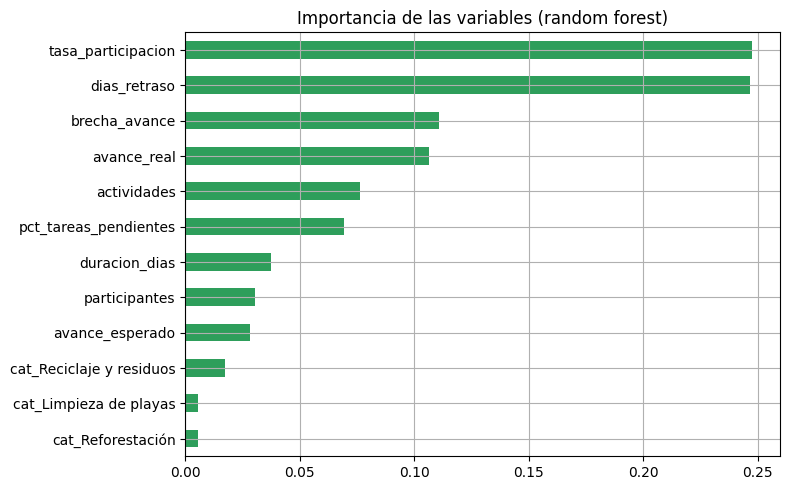

In [15]:
rf = modelos['Random forest']
imp = pd.Series(rf.feature_importances_, index=COLUMNAS).sort_values()
imp[imp > 0.005].plot(kind='barh', color='#2e9e5b', figsize=(8, 5))
plt.title('Importancia de las variables (random forest)'); plt.tight_layout(); plt.show()

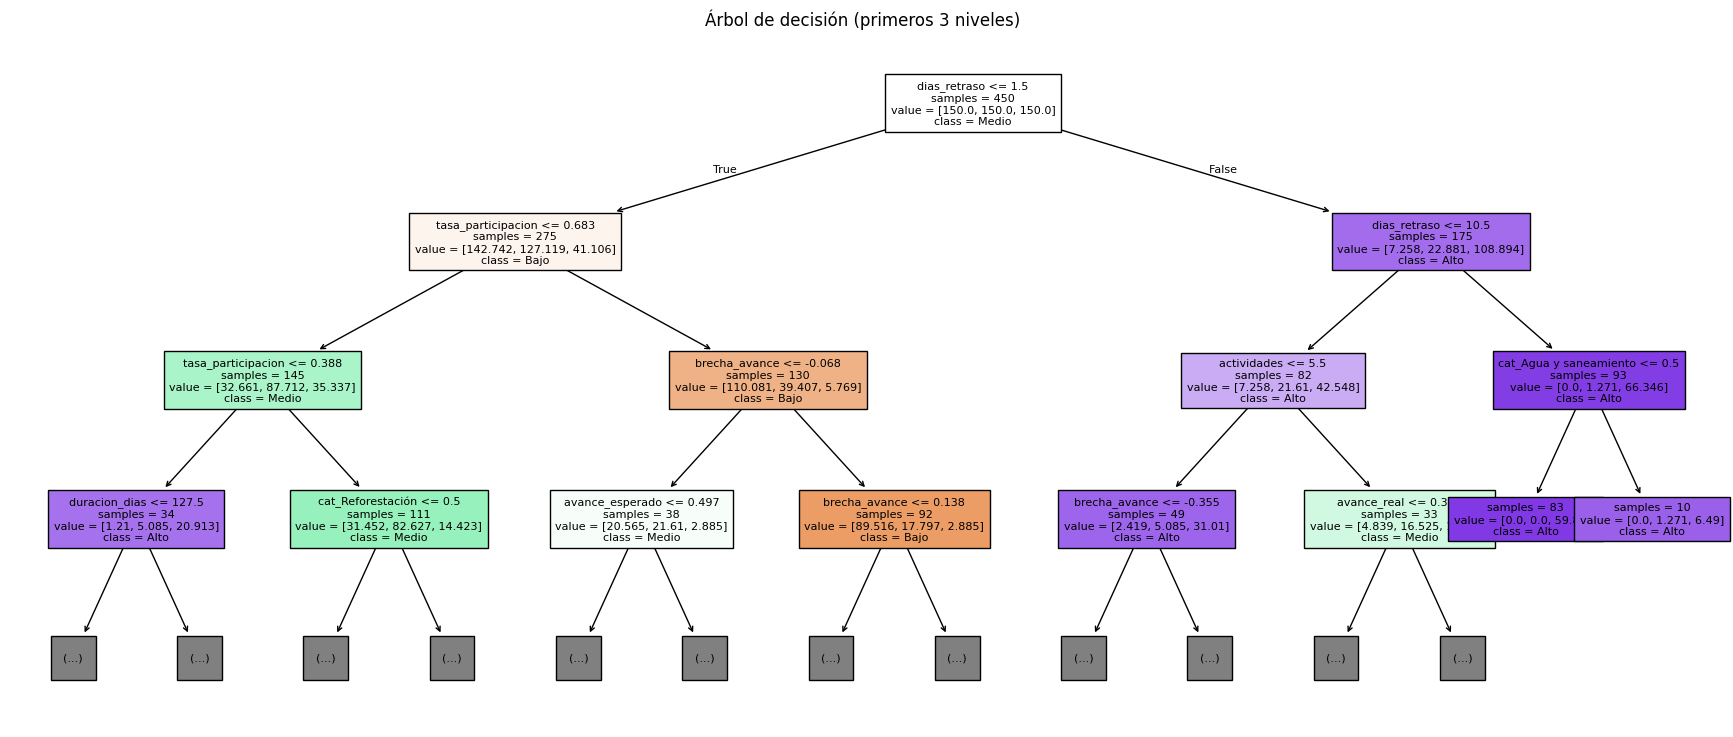

In [16]:
arbol = modelos['Árbol de decisión']
plt.figure(figsize=(22, 9))
plot_tree(arbol, feature_names=COLUMNAS, class_names=ORDEN, filled=True, max_depth=3, fontsize=8, impurity=False)
plt.title('Árbol de decisión (primeros 3 niveles)'); plt.show()

## 6. Elección del modelo

Se elige el modelo con mejor **F1 macro en validación cruzada**. Si la diferencia con el árbol de decisión es menor a 0,02, se prefiere el árbol porque es más fácil de explicar y genera un código Java más pequeño.

In [17]:
mejor = tabla_res['F1 macro (CV)'].idxmax()
if tabla_res.loc[mejor, 'F1 macro (CV)'] - tabla_res.loc['Árbol de decisión', 'F1 macro (CV)'] < 0.02:
    mejor = 'Árbol de decisión'
modelo_final = modelos[mejor]
print('Modelo elegido:', mejor)
print(tabla_res.loc[mejor])

Modelo elegido: Árbol de decisión
F1 macro (CV)         0.670
desv. CV              0.016
exactitud (prueba)    0.667
F1 macro (prueba)     0.649
Name: Árbol de decisión, dtype: float64


## 7. Exportar el modelo a código Java

Con **m2cgen** el modelo entrenado se convierte en una clase Java sin dependencias. Synergy llama a `ModeloRiesgo.score(vector)` y recibe las probabilidades de **[Bajo, Medio, Alto]**.

El archivo se copia en `src/main/java/com/proaula/spring/synergy/Service/ModeloRiesgo.java`.

In [18]:
import m2cgen as m2c

codigo = m2c.export_to_java(modelo_final, package_name='com.proaula.spring.synergy.Service', class_name='ModeloRiesgo')
encabezado = (
    '// Generado automáticamente desde Google Colab con m2cgen. No editar a mano.\n'
    f'// Modelo: {mejor}. Clases: 0=Bajo, 1=Medio, 2=Alto.\n'
    '// Entrada (en este orden): ' + ', '.join(COLUMNAS) + '\n'
)
with open('ModeloRiesgo.java', 'w', encoding='utf-8') as f:
    f.write(encabezado + codigo)
print('ModeloRiesgo.java:', len(codigo.splitlines()), 'líneas')

# Casos de prueba para comprobar que Java da el mismo resultado que Python
prueba = pd.DataFrame(X_pru[:25], columns=COLUMNAS)
prueba['clase_esperada'] = modelo_final.predict(X_pru[:25])
prueba.to_csv('prueba_modelo.csv', index=False)

try:
    from google.colab import files
    files.download('ModeloRiesgo.java')
except ImportError:
    pass

ModeloRiesgo.java: 96 líneas


## 8. Ejemplo: predecir un proyecto nuevo

In [19]:
ejemplo = pd.DataFrame([{
    'categoria': 'Limpieza de playas', 'dias_retraso': 12, 'pct_tareas_pendientes': 0.6, 'participantes': 6,
    'tasa_participacion': 0.5, 'duracion_dias': 120, 'avance_real': 0.4, 'avance_esperado': 0.5,
    'brecha_avance': -0.1, 'actividades': 5}])
probabilidades = modelo_final.predict_proba(construir_X(ejemplo))[0]
for nivel, p in zip(ORDEN, probabilidades):
    print(f'{nivel:6s} {p:6.1%}')
print('Predicción:', ORDEN[int(np.argmax(probabilidades))])

Bajo     0.0%
Medio    0.0%
Alto   100.0%
Predicción: Alto


## Conclusiones

- Las variables más útiles para anticipar el riesgo son la **brecha de avance** (avance real frente al esperado), el **porcentaje de tareas pendientes** y la **tasa de participación** a mitad del proyecto.
- El modelo elegido se usa dentro de Synergy: el administrador ve un **semáforo** en cada proyecto y una lista de proyectos en riesgo ordenada por prioridad; el líder ve el riesgo de sus proyectos con los motivos y una sugerencia.
- Los datos son simulados (scripts de población de Synergy). Con proyectos reales se debe volver a exportar el CSV, ejecutar este notebook y reemplazar `ModeloRiesgo.java`.